<p style="text-align:center">
    <a href="https://skills.network/?utm_medium=Exinfluencer&utm_source=Exinfluencer&utm_content=000026UJ&utm_term=10006555&utm_id=NA-SkillsNetwork-Channel-SkillsNetworkCoursesIBMDeveloperSkillsNetworkST0151ENSkillsNetwork20531532-2022-01-01" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo">
    </a>
</p>



# **Final Project: Boston Housing**


##### Estimated time needed: **60** minutes


#### Import the required libraries we need for the lab.


In [1]:
import piplite
await piplite.install(['numpy'],['pandas'])
await piplite.install(['seaborn'])

In [2]:
import pandas as pd
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as pyplot
import scipy.stats
import statsmodels.api as sm
from statsmodels.formula.api import ols

<ipython-input-2-b3fdaf15785b>:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


#### Read the dataset in the csv file from the URL


In [5]:
from js import fetch
import io

URL = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/boston_housing.csv'
resp = await fetch(URL)
boston_url = io.BytesIO((await resp.arrayBuffer()).to_py())

In [6]:
boston_df=pd.read_csv(boston_url)

#### Add your code below following the instructions given in the course to complete the peer graded assignment


In [8]:
# Task 1.1 Display the first 5 Rows of the dataset.

print(boston_df.head())

   Unnamed: 0     CRIM    ZN  INDUS  CHAS    NOX     RM   AGE     DIS  RAD  \
0           0  0.00632  18.0   2.31   0.0  0.538  6.575  65.2  4.0900  1.0   
1           1  0.02731   0.0   7.07   0.0  0.469  6.421  78.9  4.9671  2.0   
2           2  0.02729   0.0   7.07   0.0  0.469  7.185  61.1  4.9671  2.0   
3           3  0.03237   0.0   2.18   0.0  0.458  6.998  45.8  6.0622  3.0   
4           4  0.06905   0.0   2.18   0.0  0.458  7.147  54.2  6.0622  3.0   

     TAX  PTRATIO  LSTAT  MEDV  
0  296.0     15.3   4.98  24.0  
1  242.0     17.8   9.14  21.6  
2  242.0     17.8   4.03  34.7  
3  222.0     18.7   2.94  33.4  
4  222.0     18.7   5.33  36.2  


In [9]:
# Task 1.2 Dsiplay the data types of each column.

print(boston_df.dtypes)

Unnamed: 0      int64
CRIM          float64
ZN            float64
INDUS         float64
CHAS          float64
NOX           float64
RM            float64
AGE           float64
DIS           float64
RAD           float64
TAX           float64
PTRATIO       float64
LSTAT         float64
MEDV          float64
dtype: object


In [10]:
#  Task 1.3 Check for missing values in each column.

print(boston_df.isna().sum())

Unnamed: 0    0
CRIM          0
ZN            0
INDUS         0
CHAS          0
NOX           0
RM            0
AGE           0
DIS           0
RAD           0
TAX           0
PTRATIO       0
LSTAT         0
MEDV          0
dtype: int64


In [12]:
#  Task 1.4 Check for duplicate rows.

boston_df.duplicated().sum()

0

In [13]:
# Task 1.5 Display the correlation matrix of the dataset.

corr_matrix = boston_df.corr(numeric_only=True)
print(corr_matrix)

            Unnamed: 0      CRIM        ZN     INDUS      CHAS       NOX  \
Unnamed: 0    1.000000  0.407407 -0.103393  0.399439 -0.003759  0.398736   
CRIM          0.407407  1.000000 -0.200469  0.406583 -0.055892  0.420972   
ZN           -0.103393 -0.200469  1.000000 -0.533828 -0.042697 -0.516604   
INDUS         0.399439  0.406583 -0.533828  1.000000  0.062938  0.763651   
CHAS         -0.003759 -0.055892 -0.042697  0.062938  1.000000  0.091203   
NOX           0.398736  0.420972 -0.516604  0.763651  0.091203  1.000000   
RM           -0.079971 -0.219247  0.311991 -0.391676  0.091251 -0.302188   
AGE           0.203784  0.352734 -0.569537  0.644779  0.086518  0.731470   
DIS          -0.302211 -0.379670  0.664408 -0.708027 -0.099176 -0.769230   
RAD           0.686002  0.625505 -0.311948  0.595129 -0.007368  0.611441   
TAX           0.666626  0.582764 -0.314563  0.720760 -0.035587  0.668023   
PTRATIO       0.291074  0.289946 -0.391679  0.383248 -0.121515  0.188933   
LSTAT       

In [11]:
# Task 2.1 Display descriptive statistics of the dataset

boston_df.describe()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,LSTAT,MEDV
count,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000,506.000000
mean,252.500000,3.613524,11.363636,11.136779,0.069170,0.554695,6.284634,68.574901,3.795043,9.549407,408.237154,18.455534,12.653063,22.532806
std,146.213884,8.601545,23.322453,6.860353,0.253994,0.115878,0.702617,28.148861,2.105710,8.707259,168.537116,2.164946,7.141062,9.197104
min,0.000000,0.006320,0.000000,0.460000,0.000000,0.385000,3.561000,2.900000,1.129600,1.000000,187.000000,12.600000,1.730000,5.000000
25%,126.250000,0.082045,0.000000,5.190000,0.000000,0.449000,5.885500,45.025000,2.100175,4.000000,279.000000,17.400000,6.950000,17.025000
50%,252.500000,0.256510,0.000000,9.690000,0.000000,0.538000,6.208500,77.500000,3.207450,5.000000,330.000000,19.050000,11.360000,21.200000
75%,378.750000,3.677083,12.500000,18.100000,0.000000,0.624000,6.623500,94.075000,5.188425,24.000000,666.000000,20.200000,16.955000,25.000000
max,505.000000,88.976200,100.000000,27.740000,1.000000,0.871000,8.780000,100.000000,12.126500,24.000000,711.000000,22.000000,37.970000,50.000000


<AxesSubplot:ylabel='MEDV'>

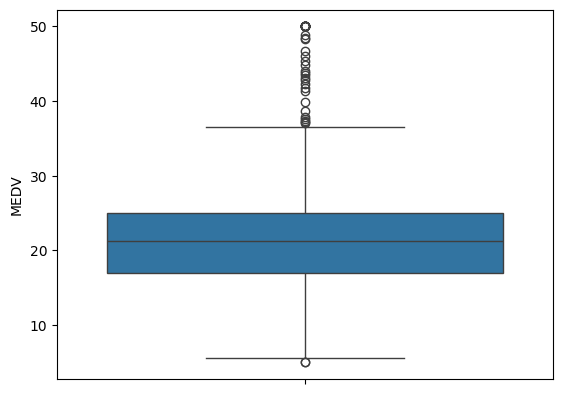

In [18]:
# Task 2.2 Create a boxplot for MEDV (Median value of owner-occupied homes).

sns.boxplot(data=boston_df ['MEDV'])


Text(0.5, 1.0, 'CHAS Bar Plot')

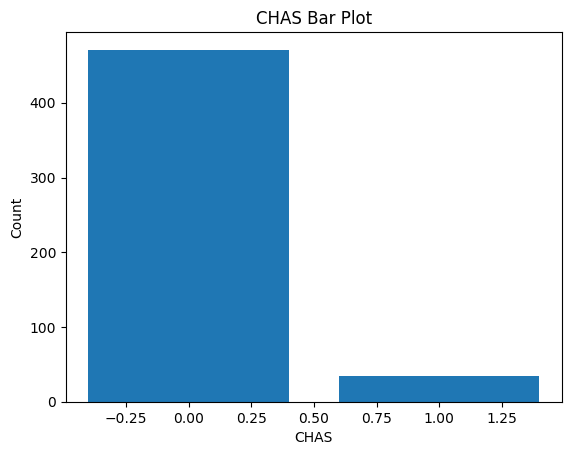

In [37]:
# Task 2.3 Create a bar plot for CHAS (Charles River dummy variable).

sorted_counts = boston_df.CHAS.value_counts().sort_index()
pyplot.bar(sorted_counts.index, sorted_counts.values)
pyplot.xlabel('CHAS')
pyplot.ylabel('Count')
pyplot.title('CHAS Bar Plot')

In [52]:
# Task 2.4 Discretize AGE into three groups and create a boxplot of MEDV versus these groups.

bins = [0, 35, 70, 100]
labels = ['35 years and younger', 'Between 35 and 70 years', '70 years and older']

# Discretize the AGE variable
boston_df['AGE_group'] = pd.cut(boston_df['AGE'], bins=bins, labels=labels)

# Generate the Boxplot
pyplot.figure(figsize=(10, 6))
sns.boxplot(x='AGE_group', y='MEDV', data=boston_df, hue='AGE_group', palette='Set2', legend=False)

pyplot.title('Median Value of Owner-Occupied Homes (MEDV) by Age Group')
pyplot.xlabel('Age Group of Homes (Proportion built pre-1940)')
pyplot.ylabel('Median Value / $1,000s')
pyplot.grid(axis='y', linestyle='--', alpha=0.5)

pyplot.show()

<class 'TypeError'>: '<' not supported between instances of 'int' and 'str'

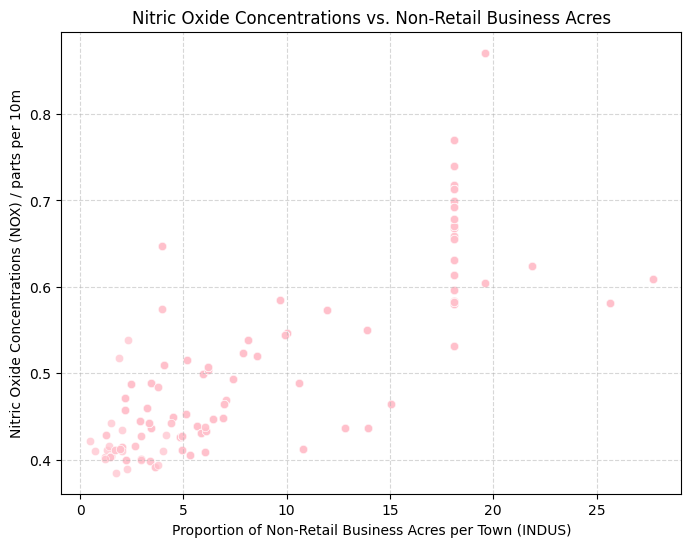

In [44]:
# Task 2.5 Create a scatter plot showing the relationship between NOX (nitric oxide concentrations) and INDUS (non-retail business acres).

pyplot.figure(figsize=(8, 6))
sns.scatterplot(x='INDUS', y='NOX', data=boston_df, color='pink', alpha=0.7)

pyplot.title('Nitric Oxide Concentrations vs. Non-Retail Business Acres')
pyplot.xlabel('Proportion of Non-Retail Business Acres per Town (INDUS)')
pyplot.ylabel('Nitric Oxide Concentrations (NOX) / parts per 10m')
pyplot.grid(True, linestyle='--', alpha=0.5)
pyplot.show()

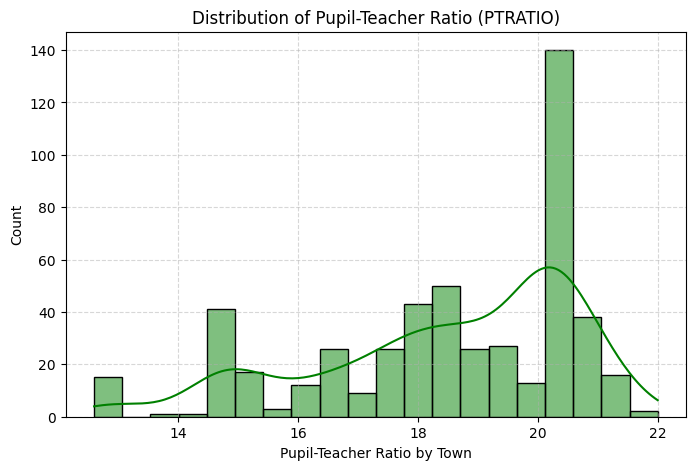

In [46]:
# Task 2.6 Create a histogram for PTRATIO (pupil-teacher ratio).

pyplot.figure(figsize=(8, 5))
sns.histplot(x='PTRATIO', data=boston_df, bins=20, color='green', kde=True)

pyplot.title('Distribution of Pupil-Teacher Ratio (PTRATIO)')
pyplot.xlabel('Pupil-Teacher Ratio by Town')
pyplot.ylabel('Count')
pyplot.grid(True, linestyle='--', alpha=0.5)
pyplot.show()

In [48]:
# Task 3.1 Use Levene’s test to check if the variances of MEDV for homes bounded by the Charles River (CHAS = 1) and those not bounded (CHAS = 0) are equal.

river_bounded = boston_df[boston_df['CHAS'] == 1]['MEDV']
not_bounded = boston_df[boston_df['CHAS'] == 0]['MEDV']

stat, p_value = scipy.stats.levene(river_bounded, not_bounded)

print(f"Levene Statistic: {stat:.4f}")
print(f"p-value: {p_value:.4f}")


Levene Statistic: 4.5903
p-value: 0.0326


In [50]:
# Task 3.2 Perform a T-test to determine if there is a significant difference in MEDV between homes bounded and not bounded by the Charles River.

river_bounded = boston_df[boston_df['CHAS'] == 1]['MEDV']
not_bounded = boston_df[boston_df['CHAS'] == 0]['MEDV']

t_stat, p_value = scipy.stats.ttest_ind(river_bounded, not_bounded, equal_var=False)

print(f"Welch's T-Statistic: {t_stat:.4f}")
print(f"p-value: {p_value:.4f}")

Welch's T-Statistic: 3.1133
p-value: 0.0036


In [53]:
# Task 3.3 Conduct an ANOVA test to compare MEDV among the three AGE groups created earlier.

bins = [0, 35, 70, 100]
labels = ['35 years and younger', 'Between 35 and 70 years', '70 years and older']
boston_df['AGE_group'] = pd.cut(boston_df['AGE'], bins=bins, labels=labels)

group1 = boston_df[boston_df['AGE_group'] == '35 years and younger']['MEDV']
group2 = boston_df[boston_df['AGE_group'] == 'Between 35 and 70 years']['MEDV']
group3 = boston_df[boston_df['AGE_group'] == '70 years and older']['MEDV']

f_stat, p_val = stats.f_oneway(group1, group2, group3)

print(f"F-Statistic: {f_stat:.3f}")
print(f"p-value: {p_val:.3e}")

<class 'TypeError'>: '<' not supported between instances of 'int' and 'str'

In [54]:
# Task 3.4 Perform a Pearson correlation test to assess the relationship between NOX and INDUS.

r_coef, p_value = scipy.stats.pearsonr(boston_df['INDUS'], boston_df['NOX'])

print(f"Pearson Correlation Coefficient (r): {r_coef:.4f}")
print(f"p-value: {p_value:.4e}")

Pearson Correlation Coefficient (r): 0.7637
p-value: 7.9134e-98


In [56]:
# Task 3.5 Fit a simple linear regression model to evaluate the impact of DIS (distance to employment centres) on MEDV. Report and interpret the regression results.

X = sm.add_constant(boston_df['DIS']) 
y = boston_df['MEDV']

model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   MEDV   R-squared:                       0.062
Model:                            OLS   Adj. R-squared:                  0.061
Method:                 Least Squares   F-statistic:                     33.58
Date:                Mon, 19 Oct 2026   Prob (F-statistic):           1.21e-08
Time:                        11:31:18   Log-Likelihood:                -1823.9
No. Observations:                 506   AIC:                             3652.
Df Residuals:                     504   BIC:                             3660.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         18.3901      0.817     22.499      0.0